# Backtest Autopsy #4: a free-data FX factor strategy (spot factors, CFTC positioning, policy rates), no signal

**Tags:** no signal (primary), cost model (secondary)

## TL;DR

* **Idea.** Rank seven currencies each day by a blend of three free signals: a spot factor (multi-horizon momentum, short-term reversal and a range-breakout position of the pairs), the CFTC "leveraged money" net positioning, and the central-bank policy-rate level. Hold a capped, currency-neutral book that is long the top-ranked currencies and short the bottom-ranked ones, via six USD pairs, at executable bid/ask prices. A second, secondary layer adds a walk-forward ridge-logistic overlay.
* **Result.** The headline strategy (spot factor + COT + rates) returns **-10.9%** net over the development window on 100,000 USD of illustrative equity, a CAGR of **-1.63%** and an annualised Sharpe of **-0.65**, on 2,156 rebalancing days. The retrospective window (looked at before, never used for a choice) is -2.3%.
* **Verdict number.** The score has no rank information about the next day's currency return: mean daily rank information coefficient (IC) 0.0131, t-statistic 1.32; the directional hit rate is 50.2% with a 95% interval of [49.4%, 51.1%]; and shuffling the days of the held weights beats the actual gross P&L 87% of the time (permutation p = 0.87). There is no gross edge to begin with (gross return -4.7%, gross Sharpe -0.27 with a 90% interval of [-0.76, 0.29]); the quoted spread and the commission then take a further 6.7% of equity.
* **Why it matters.** Free, well-documented, economically motivated factors can be assembled into a clean, capped, executable book and still carry no tradable information at a daily horizon. The test that shows it needs no costs.
* **Sensitivity.** A weekly variant (Friday anchor, persistence gate, turnover buffer, next-close execution) cuts turnover by about 85% and the loss, and it does not turn the sign: section 12.

> Outputs below come from a run on the real data. With `AUTOPSY_SYNTHETIC=1` the notebook runs end to end on synthetic quotes, positioning and rates with the same schema and will **not** reproduce the failure (a random walk has no factor structure).

### Prerequisites

* Python 3.10+, `numpy`, `pandas`, `scipy`, `matplotlib`, `pyarrow`, and the shared package `autopsy_common` (`pip install -e ../..`).
* Familiarity with: cross-sectional factor portfolios, currency-neutral exposure, the CFTC Commitments of Traders report and its publication lag, rank information coefficients, and the difference between gross and net P&L.
* Data: your own copies of the three public or broker inputs described in section 2, in a folder named by `AUTOPSY_DATA_DIR`. No data is shipped with this repository.

## 1. Settings (control panel)

Every governing constant lives in one dictionary. The values below are the starting point for this case. No parameter search is performed, and nothing below was tuned on the result. Change them and re-run the test to see whether the verdict holds.

* `AUTOPSY_SYNTHETIC=1` builds synthetic quotes, positioning and rates (same schema, no vendor data).
* `AUTOPSY_DATA_DIR` points at the folder holding your three inputs.

The development window is the evidence; everything from the retrospective start onward was looked at before this write-up and is reported separately. The book is **capped and currency-neutral by construction**: at most 25% of equity in any one currency, 80% target gross exposure, never more than 1x gross leverage across the six pairs.

In [ ]:
from __future__ import annotations

import json
import math
import os
import re
import time
import warnings
import zipfile
from pathlib import Path
from typing import Any, Dict, Iterable, List, Mapping, Optional, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from autopsy_common.data import use_synthetic
from autopsy_common.metrics import block_bootstrap_sharpe, bootstrap_mean_ci, cross_sectional_rank_ic
from autopsy_common.perf import performance_summary
from autopsy_common.plots import (plot_bar_contribution, plot_capital_sweep, plot_cost_decomposition, plot_drawdown,
                                  plot_equity, plot_exposure_turnover, plot_monthly_heatmap, plot_return_distribution,
                                  plot_rolling_risk, plot_yearly_bars)
from autopsy_common.schema import check_schema
from autopsy_common.sweep import capital_sweep

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})
SYNTHETIC = use_synthetic()
DATA_DIR = Path(os.environ["AUTOPSY_DATA_DIR"]) if os.environ.get("AUTOPSY_DATA_DIR") else None
FX_FILE = "merged_forex_data_with_xauusd.csv"     # wide minute-level bid/ask file
DAILY_FILE = "fx_daily_bid_ask.parquet"           # daily cache built by this notebook if absent
COT_DIR = "cftc_cot_fx"                           # folder of CFTC annual archives fut_fin_txt_<year>.zip
BIS_FILE = "WS_CBPOL_csv_col.csv"                 # BIS central bank policy rates, wide daily file
RESULTS: Dict[str, Any] = {}

PAIRS = ("AUDUSD", "EURUSD", "GBPUSD", "USDCAD", "USDCHF", "USDJPY")
CURRENCIES = ("AUD", "CAD", "CHF", "EUR", "GBP", "JPY", "USD")
PAIR_CURRENCIES = {pair: (pair[:3], pair[3:]) for pair in PAIRS}
# Official primary financial-futures contract names. A substring match would also select EUR/GBP and EUR/JPY cross
# contracts. GBP has two historical aliases; duplicate report dates across them remain a hard error. USD uses the ICE
# US Dollar Index future, mapped as a USD-strength instrument unlike the six non-USD futures.
COT_MARKET_NAMES = {
    "AUD": ("AUSTRALIAN DOLLAR - CHICAGO MERCANTILE EXCHANGE",),
    "CAD": ("CANADIAN DOLLAR - CHICAGO MERCANTILE EXCHANGE",),
    "CHF": ("SWISS FRANC - CHICAGO MERCANTILE EXCHANGE",),
    "EUR": ("EURO FX - CHICAGO MERCANTILE EXCHANGE",),
    "GBP": ("BRITISH POUND - CHICAGO MERCANTILE EXCHANGE", "BRITISH POUND STERLING - CHICAGO MERCANTILE EXCHANGE"),
    "JPY": ("JAPANESE YEN - CHICAGO MERCANTILE EXCHANGE",),
    "USD": ("U.S. DOLLAR INDEX - ICE FUTURES U.S.", "US DOLLAR INDEX - ICE FUTURES U.S."),
}
BIS_AREA_TO_CURRENCY = {"AU": "AUD", "CA": "CAD", "CH": "CHF", "XM": "EUR", "GB": "GBP", "JP": "JPY", "US": "USD"}

PARAMS: Dict[str, Any] = dict(
    capital=100_000.0,                      # illustrative initial equity in USD (an assumption; see the capital sweep)
    feature_start="2017-01-01",              # first day of quotes and positioning loaded (feature look-back)
    development_start="2018-01-01", development_end="2024-12-31", retrospective_start="2025-01-01",
    bis_start="2018-01-01", bis_end="2025-12-31",   # window of the policy-rate extract

    # spot factor windows (trading days)
    momentum_windows=(21, 63, 126), reversal_window=5, vol_window=21, breakout_window=63,
    # CFTC leveraged-money positioning
    cot_z_window_weeks=156, cot_min_weeks=52, cot_lag_business_days=4,   # Tuesday report usable on the next Monday
    # score blend: spot factor, positioning, policy-rate level
    w_spot=0.60, w_cot=0.30, w_rate=0.10,
    # portfolio rules
    min_currencies_for_trade=5, min_score_dispersion=0.15, min_max_abs_score=0.15,
    currency_exposure_cap=0.25, target_gross_exposure=0.80, max_gross_leverage=1.00,
    # costs: quoted half-spread at the close plus a flat one-way commission add-on
    commission_bps_one_way=0.50, cost_multiplier=1.0,
    # secondary walk-forward ridge-logistic overlay
    ml_train_days=756, ml_test_days=63, ml_min_train_rows=500, ml_l2=8.0, ml_learning_rate=0.08, ml_iterations=500,
    ml_min_confidence=0.04, ml_weight=0.30,
    # hurdles of the decision rule, fixed in advance
    cagr_band=(0.05, 0.15), min_trades=30, year_positive_min=0.60, pair_positive_min=0.50,
    # reporting
    trading_days=252, n_permutations=2000, n_bootstrap=2000, random_seed=11,
)
WEEKLY: Dict[str, Any] = dict(                # sensitivity variant, section 12 (fixed before looking at its result)
    medium_momentum_days=63, slow_momentum_days=126, short_reversal_days=5, volatility_days=21,
    short_reversal_weight=0.25, short_reversal_trend_gate_z=1.0, cot_weight=0.30, cot_disagreement_multiplier=0.50,
    signal_persistence_weeks=2, turnover_buffer_max_weight_change=0.05,
)
print(f"mode: {'SYNTHETIC' if SYNTHETIC else 'REAL DATA'} | pairs: {len(PAIRS)} | currencies: {len(CURRENCIES)}")

mode: REAL DATA | pairs: 6 | currencies: 7


## 2. Data

### 2.1 Source recipe

| Input | Vendor / product | Frequency | Notes |
|---|---|---|---|
| FX quotes | Interactive Brokers historical data API, FX contracts, `BID` and `ASK` bar series (terms of use: verify before publishing any value) | 1 minute, collapsed to a daily bid/ask close | six USD pairs; naive timestamps in a fixed UTC-5 offset |
| Positioning | CFTC *Traders in Financial Futures* ("Financial Futures only"), annual archives `fut_fin_txt_<year>.zip` from the CFTC historical compressed files page | weekly (Tuesday positions) | public domain; leveraged-money long, short and open interest |
| Policy rates | Bank for International Settlements central bank policy rates bulk file `WS_CBPOL_csv_col.csv` (`data.bis.org`, bulk downloads) | daily | seven economies mapped to seven currencies |

**How to rebuild.** The minute file is one wide table with a `timestamp` column and `<PAIR>_final_df__bid_close` / `<PAIR>_final_df__ask_close` for each pair. The CFTC archives are placed unzipped-as-downloaded in a folder; the BIS file is the extracted bulk CSV. The notebook never downloads anything.

**Timing assumptions that matter.**

* The CFTC does not publish a historical release-date series. Each Tuesday report is made tradable **four business days later** (the next Monday), which is later than the usual Friday release. Delayed holiday releases are therefore conservative rather than guessed.
* The policy-rate observation of day `t` is **not** used at the close of `t`: the join takes the strictly prior observation.
* Policy rates are a financing *proxy*, not broker swap points. No carry is earned or charged.

### 2.2 What the strategy consumes

Three tables, each with a key and a schema check below.

| Table | Row definition | Key | Columns used |
|---|---|---|---|
| daily quotes | one pair on one calendar day | `(date, asset)` | `date`, `asset`, `bid_close`, `ask_close` (last valid quote of the day; rows with a non-positive bid or a crossed quote are dropped before the collapse) |
| positioning | one currency's futures contract on one report date | `(currency, report_date)` | `net_leveraged_pct_open_interest` = (leveraged long - leveraged short) / open interest |
| policy rates | one currency on one observation day | `(currency, observation_date)` | `policy_rate` in percent |

Nulls: none after the filters above; a currency with no observation yet simply has no feature that day.

In [ ]:
DAILY_SCHEMA = {"date": "datetime", "asset": "string", "bid_close": "float64", "ask_close": "float64"}
DAILY_KEY = ["date", "asset"]
COT_SCHEMA = {"currency": "string", "report_date": "datetime", "open_interest": "float64",
              "leveraged_long": "float64", "leveraged_short": "float64"}
COT_KEY = ["currency", "report_date"]
RATE_SCHEMA = {"currency": "string", "observation_date": "datetime", "policy_rate": "float64"}
RATE_KEY = ["currency", "observation_date"]


def read_daily_quotes_from_minute(csv_path: Path, pairs, start: pd.Timestamp, chunksize: int = 300_000) -> pd.DataFrame:
    """Chunked read of the wide minute file (timestamp plus bid/ask closes), then the last VALID quote of each
    calendar day per pair (bid > 0 and ask >= bid)."""
    usecols = ["timestamp"] + [f"{p}_final_df__{side}_close" for p in pairs for side in ("bid", "ask")]
    parts = []
    for chunk in pd.read_csv(csv_path, usecols=usecols, chunksize=chunksize):
        chunk["timestamp"] = pd.to_datetime(chunk["timestamp"], errors="coerce")
        chunk = chunk.dropna(subset=["timestamp"])
        if chunk.empty or chunk["timestamp"].max() < start:
            continue
        parts.append(chunk[chunk["timestamp"] >= start])
    raw = pd.concat(parts, ignore_index=True).sort_values("timestamp").drop_duplicates("timestamp", keep="last")
    frames = []
    for pair in pairs:
        bid, ask = f"{pair}_final_df__bid_close", f"{pair}_final_df__ask_close"
        src = raw[["timestamp", bid, ask]].copy()
        src[bid] = pd.to_numeric(src[bid], errors="coerce")
        src[ask] = pd.to_numeric(src[ask], errors="coerce")
        src = src[(src[bid] > 0) & (src[ask] >= src[bid])]
        day = src["timestamp"].dt.normalize().rename("date")
        daily = src.groupby(day, sort=True).agg(bid_close=(bid, "last"), ask_close=(ask, "last")).reset_index()
        daily.insert(1, "asset", pair)
        frames.append(daily)
    out = pd.concat(frames, ignore_index=True)
    return out.sort_values(DAILY_KEY).reset_index(drop=True)


def norm_name(name: str) -> str:
    return "".join(ch for ch in str(name).upper() if ch.isalnum())


def first_column(columns: Iterable[str], candidates: Iterable[str]) -> Optional[str]:
    available = {norm_name(c): c for c in columns}
    for cand in candidates:
        if norm_name(cand) in available:
            return available[norm_name(cand)]
    return None


def read_cot(cot_dir: Path, start: pd.Timestamp, end: pd.Timestamp) -> pd.DataFrame:
    """Parse the CFTC annual archives into one row per (currency, report date). A missing year is a hard error:
    missing coverage is never fabricated."""
    records = []
    for year in range(start.year, end.year + 1):
        archive = cot_dir / f"fut_fin_txt_{year}.zip"
        if not archive.is_file():
            raise FileNotFoundError(f"missing CFTC archive for {year}: {archive.name}")
        with zipfile.ZipFile(archive) as bundle:
            members = [n for n in bundle.namelist() if n.lower().endswith((".txt", ".csv")) and "fin" in n.lower()]
            members = members or [n for n in bundle.namelist() if n.lower().endswith((".txt", ".csv"))]
            member = max(members, key=lambda n: bundle.getinfo(n).file_size)
            with bundle.open(member) as handle:
                raw = pd.read_csv(handle, low_memory=False, encoding="latin-1")
        cols = {"market": first_column(raw.columns, ("Market_and_Exchange_Names", "Market and Exchange Names")),
                "report_date": first_column(raw.columns, ("Report_Date_as_YYYY-MM-DD", "Report Date as YYYY-MM-DD")),
                "open_interest": first_column(raw.columns, ("Open_Interest_All", "Open Interest All")),
                "leveraged_long": first_column(raw.columns, ("Lev_Money_Positions_Long_All", "Lev Money Positions Long All")),
                "leveraged_short": first_column(raw.columns, ("Lev_Money_Positions_Short_All", "Lev Money Positions Short All"))}
        missing = [k for k, v in cols.items() if v is None]
        if missing:
            raise RuntimeError(f"{archive.name} lacks required CFTC fields {missing}")
        raw = raw[[cols[k] for k in cols]].copy()
        raw.columns = ["market_name", "report_date", "open_interest", "leveraged_long", "leveraged_short"]
        raw["market_name"] = raw["market_name"].astype(str).str.upper()
        raw["report_date"] = pd.to_datetime(raw["report_date"], errors="coerce").dt.normalize()
        for c in ("open_interest", "leveraged_long", "leveraged_short"):
            raw[c] = pd.to_numeric(raw[c], errors="coerce").astype("float64")
        raw = raw[raw["report_date"].notna() & (raw["open_interest"] > 0)]
        for currency, names in COT_MARKET_NAMES.items():
            hit = raw[raw["market_name"].isin(names)].copy()
            if not hit.empty:
                hit["currency"] = currency
                records.append(hit)
    cot = pd.concat(records, ignore_index=True)
    cot = cot[(cot["report_date"] >= start) & (cot["report_date"] <= end)]
    if cot.duplicated(["currency", "report_date"]).any():
        raise RuntimeError("ambiguous duplicate CFTC currency/report-date records")
    cot = cot[["currency", "report_date", "open_interest", "leveraged_long", "leveraged_short"]]
    return cot.sort_values(COT_KEY).reset_index(drop=True)


def read_bis_rates(csv_path: Path, start: pd.Timestamp, end: pd.Timestamp) -> pd.DataFrame:
    """Daily policy rates of the seven economies from the BIS wide file, restricted to [start, end]."""
    header = pd.read_csv(csv_path, nrows=0).columns.tolist()
    day_cols = [c for c in header if re.fullmatch(r"\d{4}-\d{2}-\d{2}", str(c)) and start <= pd.Timestamp(c) <= end]
    wide = pd.read_csv(csv_path, usecols=["FREQ", "REF_AREA", "Series"] + day_cols)
    wide = wide[(wide["FREQ"] == "D") & wide["REF_AREA"].isin(BIS_AREA_TO_CURRENCY)]
    long = wide.melt(id_vars=["REF_AREA", "Series"], value_vars=day_cols, var_name="observation_date", value_name="policy_rate")
    long["currency"] = long["REF_AREA"].map(BIS_AREA_TO_CURRENCY)
    long["observation_date"] = pd.to_datetime(long["observation_date"])
    long["policy_rate"] = pd.to_numeric(long["policy_rate"], errors="coerce")
    long = long.dropna(subset=["policy_rate"])
    if long.duplicated(RATE_KEY).any():
        raise RuntimeError("daily BIS input contains duplicate currency/date rows")
    return long[RATE_KEY + ["policy_rate"]].sort_values(RATE_KEY).reset_index(drop=True)


def synthetic_inputs(seed: int = 5, n_days: int = 2500, start: str = "2017-01-02"):
    """Synthetic quotes, positioning and rates with the same schema. Random walks: no factor structure by construction."""
    rng = np.random.default_rng(seed)
    dates = pd.bdate_range(start, periods=n_days)
    common = rng.normal(0.0, 0.003, n_days)
    frames = []
    for i, pair in enumerate(PAIRS):
        level = (0.7, 1.1, 1.3, 1.3, 0.9, 110.0)[i]
        mid = level * np.exp(np.cumsum(rng.normal(0.0, 0.005, n_days) + common))
        half = mid * 0.00005
        frames.append(pd.DataFrame({"date": dates, "asset": pair, "bid_close": np.round(mid - half, 6),
                                    "ask_close": np.round(mid + half, 6)}))
    quotes = pd.concat(frames, ignore_index=True).sort_values(DAILY_KEY).reset_index(drop=True)
    weeks = pd.date_range(dates[0], dates[-1], freq="W-TUE")
    cot = []
    for cur in CURRENCIES:
        level = np.cumsum(rng.normal(0.0, 0.02, len(weeks)))
        oi = np.round(rng.uniform(1e5, 3e5, len(weeks)))
        net = np.tanh(level) * oi * 0.3
        cot.append(pd.DataFrame({"currency": cur, "report_date": weeks, "open_interest": oi,
                                 "leveraged_long": np.round(np.maximum(net, 0) + oi * 0.1),
                                 "leveraged_short": np.round(np.maximum(-net, 0) + oi * 0.1)}))
    cot = pd.concat(cot, ignore_index=True).sort_values(COT_KEY).reset_index(drop=True)
    rates = []
    for cur in CURRENCIES:
        steps = np.cumsum(rng.choice([0.0, 0.0, 0.0, 0.25, -0.25], size=n_days, p=[0.9, 0.04, 0.04, 0.01, 0.01]))
        rates.append(pd.DataFrame({"currency": cur, "observation_date": dates, "policy_rate": np.round(2.0 + steps, 4)}))
    rates = pd.concat(rates, ignore_index=True).sort_values(RATE_KEY).reset_index(drop=True)
    return quotes, cot, rates


def load_inputs(p: Dict[str, Any]):
    if SYNTHETIC:
        quotes, cot, rates = synthetic_inputs()
    else:
        if DATA_DIR is None:
            raise RuntimeError("Set AUTOPSY_SYNTHETIC=1, or AUTOPSY_DATA_DIR to the folder with the three inputs.")
        cache = DATA_DIR / DAILY_FILE
        if cache.exists():
            quotes = pd.read_parquet(cache)
        else:
            quotes = read_daily_quotes_from_minute(DATA_DIR / FX_FILE, PAIRS, pd.Timestamp(p["feature_start"]))
            quotes.to_parquet(cache, index=False)
        common_end = quotes.groupby("asset")["date"].max().min()
        cot = read_cot(DATA_DIR / COT_DIR, pd.Timestamp(p["feature_start"]), common_end)
        rates = read_bis_rates(DATA_DIR / BIS_FILE, pd.Timestamp(p["bis_start"]), pd.Timestamp(p["bis_end"]))
    quotes = quotes.sort_values(DAILY_KEY).reset_index(drop=True)[list(DAILY_SCHEMA)]
    check_schema(quotes, DAILY_SCHEMA, DAILY_KEY)
    cot = cot.sort_values(COT_KEY).reset_index(drop=True)[list(COT_SCHEMA)]
    check_schema(cot, COT_SCHEMA, COT_KEY)
    rates = rates.sort_values(RATE_KEY).reset_index(drop=True)[list(RATE_SCHEMA)]
    check_schema(rates, RATE_SCHEMA, RATE_KEY)
    return quotes, cot, rates


QUOTES_LONG, COT_RAW, RATES = load_inputs(PARAMS)
print("schema checks passed for quotes, positioning and policy rates:", True)
print("quotes: key unique:", not bool(QUOTES_LONG.duplicated(DAILY_KEY).any()), "| no crossed quotes:",
      bool((QUOTES_LONG["ask_close"] >= QUOTES_LONG["bid_close"]).all()), "| no nulls:",
      not bool(QUOTES_LONG[["bid_close", "ask_close"]].isna().any().any()))
print("positioning: key unique:", not bool(COT_RAW.duplicated(COT_KEY).any()), "| all seven currencies mapped:",
      sorted(COT_RAW["currency"].unique()) == sorted(CURRENCIES))
print("policy rates: key unique:", not bool(RATES.duplicated(RATE_KEY).any()), "| all seven currencies present:",
      sorted(RATES["currency"].unique()) == sorted(CURRENCIES))

schema checks passed for quotes, positioning and policy rates: True
quotes: key unique: True | no crossed quotes: True | no nulls: True
positioning: key unique: True | all seven currencies mapped: True
policy rates: key unique: True | all seven currencies present: True


## 3. Step 1: daily mid quotes and the executable cost of a trade

For each pair the mid close is `(bid + ask) / 2`, the daily return is the mid-to-mid percentage change, and the **half-spread in basis points** is `10,000 x (ask - bid) / (2 x mid)`. A position change of size `w` (as a fraction of equity) costs `w x half-spread` plus a flat one-way commission add-on of 0.5 basis points. Marking returns at the mid and charging the half-spread on the traded amount is the one-bar equivalent of filling at the quote.

The common calendar ends on the earliest last-date across the six pairs, so no pair is extrapolated.

In [ ]:
def make_quotes(quotes_long: pd.DataFrame, p: Dict[str, Any]) -> Dict[str, pd.DataFrame]:
    out = {}
    start = pd.Timestamp(p["feature_start"])
    common_end = quotes_long.groupby("asset")["date"].max().min()
    for pair in PAIRS:
        q = quotes_long[quotes_long["asset"] == pair].set_index("date").sort_index()[["bid_close", "ask_close"]].copy()
        q["mid_close"] = (q["bid_close"] + q["ask_close"]) / 2.0
        q["mid_return"] = q["mid_close"].pct_change()
        q["half_spread_bps"] = 5000.0 * (q["ask_close"] - q["bid_close"]) / q["mid_close"]
        out[pair] = q.loc[(q.index >= start) & (q.index <= common_end)].copy()
    return out


QUOTES = make_quotes(QUOTES_LONG, PARAMS)
print("pairs with a mid and a half-spread series:", len(QUOTES), "| no non-positive mids:",
      bool(all((q["mid_close"] > 0).all() for q in QUOTES.values())))

pairs with a mid and a half-spread series: 6 | no non-positive mids: True


## 4. Step 2: currency-level features

Each pair gives a view of two currencies: long the base, short the quote. Pair-level features are therefore converted to currency-level observations with a sign (+1 for the base, -1 for the quote), and the USD feature is the average of its six pair relationships (one USD score, not six).

* **Spot factor.** Three components, each cross-sectionally standardised each day with a *robust* z-score (median and 1.4826 x median absolute deviation across the seven currencies): momentum (mean of the 21-, 63- and 126-day log-price changes), short-term reversal (minus the 5-day change) and breakout position (where the price sits in its 63-day range, minus one half). The spot score is their average.
* **Dispersion.** The cross-sectional standard deviation of the spot score. A day with low dispersion is a day with nothing to say, and the book stays flat.
* **Policy rate.** The strictly prior daily policy-rate observation, robust-z-scored across currencies.
* **Positioning.** The weekly CFTC leveraged-money net position as a share of open interest, z-scored against its own trailing 156 weeks (at least 52), clipped at +/-3, and joined at the report date plus four business days.
* **Score.** `0.60 x spot + 0.30 x positioning + 0.10 x rate`. A missing component makes the score missing: the day is skipped rather than imputed.

What can go wrong: a rolling z-score of a slow series (positioning, rates) has very few independent observations per year; and any join of a weekly series to a daily one is a place where look-ahead hides. Both joins are as-of joins on the *availability* date, not the observation date.

In [ ]:
def robust_zscore(frame: pd.DataFrame, columns: List[str]) -> pd.DataFrame:
    """Cross-sectional (per date) robust z-score: (x - median) / (1.4826 x median absolute deviation)."""
    out = frame.copy()
    for col in columns:
        med = out.groupby("date")[col].transform("median")
        scale = (out[col] - med).abs().groupby(out["date"]).transform("median") * 1.4826
        out[f"z_{col}"] = np.where(scale > 1e-12, (out[col] - med) / scale, np.nan)
    return out


def prepare_cot(cot_raw: pd.DataFrame, p: Dict[str, Any]) -> pd.DataFrame:
    cot = cot_raw.copy()
    cot["net_leveraged_pct_open_interest"] = (cot["leveraged_long"] - cot["leveraged_short"]) / cot["open_interest"]
    # No historical release-date series exists: make each Tuesday report usable four business days later.
    cot["assumed_availability_date"] = cot["report_date"] + pd.offsets.BDay(int(p["cot_lag_business_days"]))
    cot = cot.sort_values(["currency", "report_date"]).reset_index(drop=True)
    win, minw = int(p["cot_z_window_weeks"]), int(p["cot_min_weeks"])
    cot["cot_zscore"] = cot.groupby("currency", group_keys=False)["net_leveraged_pct_open_interest"].transform(
        lambda s: (s - s.rolling(win, min_periods=minw).mean()) / s.rolling(win, min_periods=minw).std(ddof=1))
    cot["cot_zscore"] = cot["cot_zscore"].clip(-3.0, 3.0)
    return cot


def build_currency_features(quotes: Mapping[str, pd.DataFrame], rates: pd.DataFrame, cot: pd.DataFrame,
                            p: Dict[str, Any]) -> pd.DataFrame:
    rows = []
    for pair, quote in quotes.items():
        base, term = PAIR_CURRENCIES[pair]
        daily = quote.copy().rename_axis("date").reset_index()
        log_price = np.log(daily["mid_close"])
        daily["pair_momentum"] = sum(log_price.diff(w) for w in p["momentum_windows"]) / len(p["momentum_windows"])
        daily["pair_reversal"] = -log_price.diff(p["reversal_window"])
        daily["pair_volatility"] = daily["mid_return"].rolling(p["vol_window"], min_periods=p["vol_window"]).std(ddof=1)
        hi = daily["mid_close"].rolling(p["breakout_window"], min_periods=p["breakout_window"]).max()
        lo = daily["mid_close"].rolling(p["breakout_window"], min_periods=p["breakout_window"]).min()
        daily["pair_breakout"] = ((daily["mid_close"] - lo) / (hi - lo)).replace([np.inf, -np.inf], np.nan) - 0.5
        for currency, sign in ((base, 1.0), (term, -1.0)):
            part = daily[["date", "pair_momentum", "pair_reversal", "pair_volatility", "pair_breakout"]].copy()
            part["currency"] = currency
            for c in ("pair_momentum", "pair_reversal", "pair_breakout"):
                part[c] *= sign
            rows.append(part)
    cur = pd.concat(rows, ignore_index=True)
    cur = cur.groupby(["date", "currency"], as_index=False).agg(
        {"pair_momentum": "mean", "pair_reversal": "mean", "pair_volatility": "mean", "pair_breakout": "mean"})
    cur = robust_zscore(cur, ["pair_momentum", "pair_reversal", "pair_breakout"])
    cur["spot_factor_score"] = cur[["z_pair_momentum", "z_pair_reversal", "z_pair_breakout"]].mean(axis=1, skipna=False)
    cur["cross_section_dispersion"] = cur.groupby("date")["spot_factor_score"].transform("std")
    cur = cur.sort_values(["currency", "date"])
    dates = cur[["date", "currency"]].drop_duplicates().sort_values(["currency", "date"])
    # strictly prior policy-rate observation: a rate dated t is not used at the close of t
    rate_rows = []
    for currency, left in dates.groupby("currency", sort=False):
        src = rates.loc[rates["currency"] == currency, ["observation_date", "policy_rate"]].sort_values("observation_date")
        joined = pd.merge_asof(left.sort_values("date"), src, left_on="date", right_on="observation_date",
                               direction="backward", allow_exact_matches=False)
        rate_rows.append(joined.rename(columns={"policy_rate": "policy_rate_pct"}))
    cur = cur.merge(pd.concat(rate_rows, ignore_index=True), on=["date", "currency"], how="left", validate="one_to_one")
    cur = robust_zscore(cur, ["policy_rate_pct"])
    cur["rate_feature"] = cur["z_policy_rate_pct"]
    cot_rows = []
    for currency, left in dates.groupby("currency", sort=False):
        src = cot.loc[cot["currency"] == currency, ["assumed_availability_date", "report_date",
                                                    "net_leveraged_pct_open_interest", "cot_zscore"]].sort_values("assumed_availability_date")
        cot_rows.append(pd.merge_asof(left.sort_values("date"), src, left_on="date", right_on="assumed_availability_date",
                                      direction="backward", allow_exact_matches=True))
    cur = cur.merge(pd.concat(cot_rows, ignore_index=True), on=["date", "currency"], how="left", validate="one_to_one")
    cur["cot_feature"] = cur["cot_zscore"].clip(-3.0, 3.0)
    cur["factor_cot_score"] = p["w_spot"] * cur["spot_factor_score"] + p["w_cot"] * cur["cot_feature"] + p["w_rate"] * cur["rate_feature"]
    return cur.sort_values(["date", "currency"]).reset_index(drop=True)


def currency_returns_from_pairs(quotes: Mapping[str, pd.DataFrame]) -> pd.DataFrame:
    """Realised currency return of each day and the NEXT day's (the label used only for scoring and for the overlay)."""
    rows = []
    for pair, quote in quotes.items():
        base, term = PAIR_CURRENCIES[pair]
        ret = quote["mid_return"].rename("pair_return").rename_axis("date").reset_index()
        for currency, sign in ((base, 1.0), (term, -1.0)):
            item = ret.copy()
            item["currency"] = currency
            item["currency_return"] = sign * item["pair_return"]
            rows.append(item[["date", "currency", "currency_return"]])
    out = pd.concat(rows, ignore_index=True).groupby(["date", "currency"], as_index=False)["currency_return"].mean()
    out = out.sort_values(["currency", "date"])
    out["next_currency_return"] = out.groupby("currency")["currency_return"].shift(-1)
    return out


t0 = time.time()
COT = prepare_cot(COT_RAW, PARAMS)
FEATURES = build_currency_features(QUOTES, RATES, COT, PARAMS)
CUR_RET = currency_returns_from_pairs(QUOTES)
print(f"features built in {time.time() - t0:.1f}s | columns: {len(FEATURES.columns)}")

features built in 0.1s | columns: 21


## 5. Step 3: the secondary overlay (a walk-forward ridge-logistic classifier)

The notebook adds a **pooled** classifier as a secondary layer: every 63 trading days it refits, on the trailing 756 days of currency-days, a ridge-penalised logistic regression (500 gradient steps, L2 = 8, features standardised on the training rows) that predicts whether a currency's *next-day* return is positive from seven features (momentum, reversal, volatility, breakout, dispersion, positioning and policy-rate z-scores). Its predictions are used **only on the following 63 days**, so each prediction comes from a model fit on earlier rows. The overlay score blends 70% of the factor score with 30% of the signed probability (`2 x (p - 0.5)`) and is **skipped** (NaN) when the probability is within 0.04 of one half.

The training rows' label is the next day's return, so the last training row's label is known only at the end of the training window: the training window ends the day before the test block starts.

What can go wrong: fitting on currency-days pooled across currencies makes the rows cross-sectionally dependent, so the effective sample is much smaller than the row count; and a classifier with seven weak features and a 50% base rate is easy to over-read.

In [ ]:
def fit_ridge_logistic(x: np.ndarray, y: np.ndarray, p: Dict[str, Any]):
    mean = x.mean(axis=0)
    scale = x.std(axis=0, ddof=0)
    scale[scale < 1e-12] = 1.0
    z = (x - mean) / scale
    design = np.column_stack([np.ones(len(z)), z])
    weights = np.zeros(design.shape[1])
    for _ in range(int(p["ml_iterations"])):
        logits = np.clip(design @ weights, -35.0, 35.0)
        probs = 1.0 / (1.0 + np.exp(-logits))
        gradient = design.T @ (probs - y) / len(y)
        gradient[1:] += p["ml_l2"] * weights[1:] / len(y)
        weights -= p["ml_learning_rate"] * gradient
    return weights, mean, scale


ML_INPUTS = ["pair_momentum", "pair_reversal", "pair_volatility", "pair_breakout", "cross_section_dispersion",
             "cot_feature", "rate_feature"]


def add_ml_overlay(features: pd.DataFrame, cur_ret: pd.DataFrame, p: Dict[str, Any]) -> Tuple[pd.DataFrame, pd.DataFrame]:
    out = features.merge(cur_ret[["date", "currency", "next_currency_return"]], on=["date", "currency"], how="left")
    out["ml_probability"] = np.nan
    folds = []
    dates = np.array(sorted(out["date"].dropna().unique()))
    for i0 in range(int(p["ml_train_days"]), len(dates), int(p["ml_test_days"])):
        test_dates = dates[i0:min(i0 + int(p["ml_test_days"]), len(dates))]
        train_dates = dates[max(0, i0 - int(p["ml_train_days"])):i0]
        train = out.loc[out["date"].isin(train_dates), ML_INPUTS + ["next_currency_return"]].dropna()
        test = out.loc[out["date"].isin(test_dates), ML_INPUTS].copy()
        if len(train) < p["ml_min_train_rows"] or len(test) == 0 or train["next_currency_return"].nunique() < 2:
            folds.append({"train_rows": len(train), "status": "skipped"})
            continue
        y = (train["next_currency_return"].to_numpy() > 0).astype(float)
        weights, mean, scale = fit_ridge_logistic(train[ML_INPUTS].to_numpy(dtype=float), y, p)
        zt = (test[ML_INPUTS].to_numpy(dtype=float) - mean) / scale
        probs = 1.0 / (1.0 + np.exp(-np.clip(np.column_stack([np.ones(len(zt)), zt]) @ weights, -35.0, 35.0)))
        out.loc[test.index, "ml_probability"] = probs
        folds.append({"train_rows": len(train), "status": "predicted"})
    out["ml_signed_score"] = 2.0 * (out["ml_probability"] - 0.5)
    out["ml_overlay_score"] = np.where(out["ml_signed_score"].abs() >= p["ml_min_confidence"],
                                       (1.0 - p["ml_weight"]) * out["factor_cot_score"] + p["ml_weight"] * out["ml_signed_score"], np.nan)
    return out, pd.DataFrame(folds)


t0 = time.time()
FEAT, ML_FOLDS = add_ml_overlay(FEATURES, CUR_RET, PARAMS)
print(f"overlay done in {time.time() - t0:.1f}s | folds predicted: {int((ML_FOLDS['status'] == 'predicted').sum())} "
      f"of {len(ML_FOLDS)}")

overlay done in 0.9s | folds predicted: 37 of 37


## 6. Step 4: from scores to a capped, currency-neutral book

For each strategy (the score column it uses) and each day:

1. Keep currencies with a valid score and a positive volatility. If fewer than five qualify, hold nothing (`insufficient_valid_currencies`). If the cross-sectional dispersion is below 0.15 (`low_score_dispersion`) or the largest absolute score is below 0.15 (`low_absolute_signal`), hold nothing.
2. Divide each score by the currency's volatility (a crude risk scaling), subtract the cross-sectional mean (currency-neutral) and scale so the absolute exposures sum to 80%.
3. Cap each currency at +/-25%, then give back the neutrality lost to the cap **only through the remaining capacity** on the required side, so that no cap is breached and the net currency exposure is zero.
4. Translate the seven currency exposures into six USD-pair weights exactly once (long a pair when its base currency is long, or when its quote currency is short).

A guard raises an error rather than return weights that break neutrality, a cap or the leverage limit.

The four strategies are: `factor_only` (spot score), `cot_only` (positioning alone), `factor_cot` (the headline score) and `ml_overlay` (the secondary layer).

In [ ]:
def bounded_exposures(scores: pd.Series, vol: pd.Series, dispersion: float, p: Dict[str, Any]) -> Tuple[pd.Series, str]:
    cap, target = p["currency_exposure_cap"], p["target_gross_exposure"]
    valid = scores.notna() & vol.notna() & (vol > 0)
    if int(valid.sum()) < p["min_currencies_for_trade"]:
        return pd.Series(0.0, index=scores.index), "insufficient_valid_currencies"
    clean = scores.loc[valid]
    if not math.isfinite(dispersion) or dispersion < p["min_score_dispersion"]:
        return pd.Series(0.0, index=scores.index), "low_score_dispersion"
    if clean.abs().max() < p["min_max_abs_score"]:
        return pd.Series(0.0, index=scores.index), "low_absolute_signal"
    raw = (clean / vol.loc[valid]).replace([np.inf, -np.inf], np.nan).dropna()
    raw = raw - raw.mean()
    gross = raw.abs().sum()
    if gross <= 1e-12:
        return pd.Series(0.0, index=scores.index), "zero_net_score"
    exposure = (raw / gross * target).clip(-cap, cap)
    residual = float(exposure.sum())
    if abs(residual) > 1e-15:
        capacity = exposure + cap if residual > 0 else cap - exposure
        total_capacity = float(capacity.sum())
        if total_capacity + 1e-12 < abs(residual):
            raise RuntimeError("currency cap leaves insufficient capacity to restore neutrality")
        exposure -= residual * capacity / total_capacity
        residual = float(exposure.sum())
        if abs(residual) > 1e-15:
            capacity = exposure + cap if residual > 0 else cap - exposure
            exposure.loc[capacity.idxmax()] -= residual
    if (abs(float(exposure.sum())) > 1e-12 or exposure.abs().max() > cap + 1e-12
            or exposure.abs().sum() > target + 1e-12 or exposure.abs().sum() > p["max_gross_leverage"] + 1e-12):
        raise RuntimeError("exposure constraints breached; refusing to produce portfolio weights")
    result = pd.Series(0.0, index=scores.index)
    result.loc[exposure.index] = exposure
    return result, "active"


def build_targets(features: pd.DataFrame, score_column: str, p: Dict[str, Any]) -> pd.DataFrame:
    out_rows = []
    for date, group in features.groupby("date", sort=True):
        group = group.set_index("currency").reindex(list(CURRENCIES))
        disp = float(group["cross_section_dispersion"].iloc[0]) if len(group) else math.nan
        exposure, state = bounded_exposures(group[score_column], group["pair_volatility"], disp, p)
        row = {"date": date, "strategy": score_column, "state": state,
               "gross_currency_exposure": float(exposure.abs().sum()), "net_currency_exposure": float(exposure.sum()),
               "max_abs_currency_exposure": float(exposure.abs().max())}
        for cur in CURRENCIES:
            row[f"currency_{cur}"] = float(exposure.loc[cur])
        for pair, (base, term) in PAIR_CURRENCIES.items():
            row[f"weight_{pair}"] = float(exposure.loc[base] if term == "USD" else -exposure.loc[term])
        out_rows.append(row)
    return pd.DataFrame(out_rows)


STRATEGY_SCORES = {"factor_only": "spot_factor_score", "cot_only": "cot_feature", "factor_cot": "factor_cot_score",
                   "ml_overlay": "ml_overlay_score"}
t0 = time.time()
TARGETS = {name: build_targets(FEAT, col, PARAMS) for name, col in STRATEGY_SCORES.items()}
print(f"targets built for {len(TARGETS)} strategies in {time.time() - t0:.1f}s")
state_share = pd.DataFrame({k: v["state"].value_counts(normalize=True) for k, v in TARGETS.items()}).fillna(0.0)
display((state_share * 100).round(1))
RESULTS["overlay_active_share"] = float(state_share.loc["active", "ml_overlay"])
RESULTS["factor_cot_active_share"] = float(state_share.loc["active", "factor_cot"])

targets built for 4 strategies in 21.3s


,factor_only,cot_only,factor_cot,ml_overlay
state,,,,
active,92.0,86.2,86.1,10.6
insufficient_valid_currencies,8.0,10.1,13.8,89.3
low_absolute_signal,0.0,0.0,0.0,0.1
low_score_dispersion,0.0,3.7,0.0,0.0


## 7. Step 5: executing the book and booking P&L

Weights decided at the close of day `t` are **held over `t+1`**: the position held on day `t` is the weight set at `t-1`. The day's gross return is `sum(held weight x pair mid return)`. Turnover is `|w_t - w_{t-1}|` per pair. The spread cost is `turnover x half-spread` and the commission is `turnover x 0.5 basis points`, both charged on the day the weight changes. Net return is gross less both. Equity compounds on net return.

The caveats are: the 2025-and-later window is **retrospective**, and policy rates are not carry.

In [ ]:
def run_portfolio(targets: pd.DataFrame, quotes: Mapping[str, pd.DataFrame], p: Dict[str, Any]) -> pd.DataFrame:
    frame = targets.copy().sort_values("date")
    for pair, quote in quotes.items():
        series = quote[["mid_return", "half_spread_bps"]].rename_axis("date").reset_index().rename(
            columns={"mid_return": f"return_{pair}", "half_spread_bps": f"half_spread_bps_{pair}"})
        frame = frame.merge(series, on="date", how="left", validate="one_to_one")
    frame["gross_leverage"] = frame[[f"weight_{pair}" for pair in PAIRS]].abs().sum(axis=1)
    if (frame["gross_leverage"] > p["max_gross_leverage"] + 1e-10).any():
        raise RuntimeError("pair gross leverage exceeds the limit")
    for pair in PAIRS:
        w = f"weight_{pair}"
        frame[f"held_{pair}"] = frame[w].shift(1).fillna(0.0)
        frame[f"turnover_{pair}"] = (frame[w] - frame[w].shift(1).fillna(0.0)).abs()
    frame["gross_return"] = sum(frame[f"held_{pair}"] * frame[f"return_{pair}"].fillna(0.0) for pair in PAIRS)
    frame["spread_cost"] = -sum(frame[f"turnover_{pair}"] * frame[f"half_spread_bps_{pair}"].fillna(0.0) / 10_000.0 for pair in PAIRS) * p["cost_multiplier"]
    frame["commission_cost"] = -p["commission_bps_one_way"] / 10_000.0 * sum(frame[f"turnover_{pair}"] for pair in PAIRS) * p["cost_multiplier"]
    frame["net_return"] = frame["gross_return"] + frame["spread_cost"] + frame["commission_cost"]
    frame["turnover"] = sum(frame[f"turnover_{pair}"] for pair in PAIRS)
    frame["trade_event"] = (frame["turnover"] > 1e-12).astype(int)
    return frame.reset_index(drop=True)


def window(frame: pd.DataFrame, scope: str, p: Dict[str, Any]) -> pd.DataFrame:
    if scope == "development":
        return frame[(frame["date"] >= p["development_start"]) & (frame["date"] <= p["development_end"])]
    return frame[frame["date"] >= p["retrospective_start"]]


def window_metrics(sample: pd.DataFrame, p: Dict[str, Any]) -> Dict[str, float]:
    returns = sample["net_return"].fillna(0.0)
    equity = (1.0 + returns).cumprod()
    elapsed = max((sample["date"].iloc[-1] - sample["date"].iloc[0]).days, 1)
    total = float(equity.iloc[-1] - 1.0)
    sd = returns.std(ddof=1)
    active = sample["gross_leverage"] > 0
    return {"total_return": total, "cagr": (1.0 + total) ** (365.25 / elapsed) - 1.0 if total > -1 else np.nan,
            "sharpe": float(math.sqrt(p["trading_days"]) * returns.mean() / sd) if sd > 0 else np.nan,
            "max_drawdown": float((equity / equity.cummax() - 1.0).min()), "trade_count": int(sample["trade_event"].sum()),
            "hit_rate": float((returns[active] > 0).mean()) if active.any() else np.nan,
            "turnover": float(sample["turnover"].sum()), "avg_exposure": float(sample["gross_leverage"].mean()),
            "gross_total_return": float((1.0 + sample["gross_return"].fillna(0.0)).prod() - 1.0),
            "spread_cost": float(-sample["spread_cost"].sum()), "commission_cost": float(-sample["commission_cost"].sum())}


def run_all(p: Dict[str, Any]) -> Dict[str, pd.DataFrame]:
    return {name: run_portfolio(t, QUOTES, p) for name, t in TARGETS.items()}


FRAMES = run_all(PARAMS)
SUMMARY = pd.DataFrame({(name, scope): window_metrics(window(fr, scope, PARAMS), PARAMS)
                        for name, fr in FRAMES.items() for scope in ("development", "retrospective")}).T
SUMMARY.index.names = ["strategy", "scope"]
print("portfolios run:", list(FRAMES))

portfolios run: ['factor_only', 'cot_only', 'factor_cot', 'ml_overlay']


## 8. Results and metrics

Net returns are the daily returns after spread and commission. The strategy defines **no benchmark**, so none is added: the zero line (cash) is the baseline, and the four strategies are compared with each other and with their own gross returns. **Exposure** is mean gross leverage across the six pairs; **turnover** is the sum of absolute weight changes over the window (a daily turnover of 1.0 would mean replacing the whole book).

In [ ]:
ppy = int(PARAMS["trading_days"])
view = SUMMARY.copy()
fmt = view.copy()
for c in ["total_return", "cagr", "max_drawdown", "hit_rate", "gross_total_return", "spread_cost", "commission_cost"]:
    fmt[c] = view[c].map(lambda v: f"{v * 100:.2f}%")
fmt["sharpe"] = view["sharpe"].map(lambda v: f"{v:.2f}")
fmt["trade_count"] = view["trade_count"].map(lambda v: f"{v:,.0f}")
fmt["turnover"] = view["turnover"].map(lambda v: f"{v:,.0f}")
fmt["avg_exposure"] = view["avg_exposure"].map(lambda v: f"{v:.2f}")
display(fmt[["total_return", "cagr", "sharpe", "max_drawdown", "trade_count", "hit_rate", "turnover", "avg_exposure",
             "gross_total_return", "spread_cost", "commission_cost"]])

dev = {n: window(f, "development", PARAMS).set_index("date") for n, f in FRAMES.items()}
net = {n: d["net_return"].fillna(0.0) for n, d in dev.items()}
gross = {n: d["gross_return"].fillna(0.0) for n, d in dev.items()}
ext = pd.DataFrame({n: performance_summary(net[n], periods_per_year=ppy, gross_returns=gross[n],
                                           turnover=dev[n]["turnover"], exposure=dev[n]["gross_leverage"]) for n in FRAMES})
display(ext.loc[["total_return", "cagr", "sharpe", "sortino", "calmar", "max_drawdown", "max_drawdown_duration",
                 "profit_factor", "skew", "kurtosis", "var_95", "cvar_95", "gross_total_return", "gross_sharpe",
                 "cost_drag_ann", "avg_turnover", "avg_exposure"]].round(4))
fc = "factor_cot"
cap = float(PARAMS["capital"])
ci_net = {n: bootstrap_mean_ci(net[n], n_boot=int(PARAMS["n_bootstrap"]), seed=int(PARAMS["random_seed"])) for n in FRAMES}
blk_net = {n: block_bootstrap_sharpe(net[n], block=10, n_boot=int(PARAMS["n_bootstrap"]), seed=int(PARAMS["random_seed"])) for n in FRAMES}
blk_gross = {n: block_bootstrap_sharpe(gross[n], block=10, n_boot=int(PARAMS["n_bootstrap"]), seed=int(PARAMS["random_seed"])) for n in FRAMES}
cis = pd.DataFrame({n: {"mean_daily_bp": ci_net[n]["mean"] * 1e4, "ci95_lo_bp": ci_net[n]["lo"] * 1e4, "ci95_hi_bp": ci_net[n]["hi"] * 1e4,
                        "net_sharpe_ci90_lo": blk_net[n]["lo"], "net_sharpe_ci90_hi": blk_net[n]["hi"],
                        "gross_sharpe_ci90_lo": blk_gross[n]["lo"], "gross_sharpe_ci90_hi": blk_gross[n]["hi"]} for n in FRAMES}).T
display(cis.round(3))
d = SUMMARY.loc[(fc, "development")]
r = SUMMARY.loc[(fc, "retrospective")]
RESULTS.update({"fc_dev_total": float(d["total_return"]), "fc_dev_cagr": float(d["cagr"]), "fc_dev_sharpe": float(d["sharpe"]),
                "fc_dev_mdd": float(d["max_drawdown"]), "fc_dev_trades": int(d["trade_count"]), "fc_turnover": float(d["turnover"]),
                "fc_dev_gross_total": float(d["gross_total_return"]), "fc_retro_total": float(r["total_return"]),
                "fc_retro_sharpe": float(r["sharpe"]), "fc_dev_usd": float(cap * d["total_return"]),
                "fc_gross_sharpe": float(ext.loc["gross_sharpe", fc]), "fc_gross_sharpe_lo": float(blk_gross[fc]["lo"]),
                "fc_gross_sharpe_hi": float(blk_gross[fc]["hi"]), "fc_net_sharpe_lo": float(blk_net[fc]["lo"]),
                "fc_net_sharpe_hi": float(blk_net[fc]["hi"]), "fc_ci_lo_bp": float(cis.loc[fc, "ci95_lo_bp"]),
                "fc_ci_hi_bp": float(cis.loc[fc, "ci95_hi_bp"]),
                "fc_spread_cost": float(d["spread_cost"]), "fc_commission_cost": float(d["commission_cost"]),
                "fc_costs_total": float(d["spread_cost"] + d["commission_cost"]),
                "fc_avg_exposure": float(d["avg_exposure"]),
                "strategies_dev": {n: {k: float(SUMMARY.loc[(n, "development"), k]) for k in
                                       ("total_return", "cagr", "sharpe", "max_drawdown", "trade_count", "turnover", "gross_total_return")} for n in FRAMES},
                "strategies_retro": {n: {k: float(SUMMARY.loc[(n, "retrospective"), k]) for k in ("total_return", "cagr", "sharpe")} for n in FRAMES}})

total_return    cagr sharpe max_drawdown  \
strategy    scope                                                    
factor_only development        -10.79%  -1.62%  -0.65      -12.90%   
            retrospective       -3.34%  -1.87%  -0.83       -3.52%   
cot_only    development         -5.05%  -0.74%  -0.33       -8.04%   
            retrospective       -0.10%  -0.06%  -0.02       -2.72%   
factor_cot  development        -10.85%  -1.63%  -0.65      -13.56%   
            retrospective       -2.32%  -1.29%  -0.62       -2.76%   
ml_overlay  development         -4.33%  -0.63%  -0.58       -6.07%   
            retrospective        0.52%   0.29%   0.60       -0.27%   

                          trade_count hit_rate turnover avg_exposure  \
strategy    scope                                                      
factor_only development         2,157   46.78%      589         0.54   
            retrospective         554   47.12%      138         0.50   
cot_only    development         2,157   48.69%      181         0.64   
            retrospective         554   50.65%       51         0.68   
factor_cot  development         2,156   48.57%      524         0.55   
            retrospective         554   48.42%      124         0.53   
ml_overlay  development           338   30.80%      138         0.06   
            retrospective         108   28.00%       45         0.07   

                          gross_total_return spread_cost commission_cost  
strategy    scope                                                         
factor_only development               -3.91%       4.48%           2.95%  
            retrospective             -0.80%       1.90%           0.69%  
cot_only    development               -3.07%       1.15%           0.91%  
            retrospective              1.16%       1.00%           0.26%  
factor_cot  development               -4.71%       4.04%           2.62%  
            retrospective              0.06%       1.78%           0.62%  
ml_overlay  development               -2.40%       1.31%           0.69%  
            retrospective              1.28%       0.53%           0.22%

,factor_only,cot_only,factor_cot,ml_overlay
total_return,-0.1079,-0.0505,-0.1085,-0.0433
cagr,-0.0131,-0.0059,-0.0131,-0.0051
sharpe,-0.6474,-0.3334,-0.6494,-0.5792
sortino,-0.8397,-0.4738,-0.7909,-0.2842
calmar,-0.1013,-0.0740,-0.0970,-0.0837
max_drawdown,-0.1290,-0.0804,-0.1356,-0.0607
max_drawdown_duration,2121.0000,2159.0000,2116.0000,1492.0000
profit_factor,0.8897,0.9433,0.8874,0.7348
skew,-0.8376,0.0172,-1.6642,-1.8275
kurtosis,10.6497,2.8220,23.9309,62.1531


,mean_daily_bp,ci95_lo_bp,ci95_hi_bp,net_sharpe_ci90_lo,net_sharpe_ci90_hi,gross_sharpe_ci90_lo,gross_sharpe_ci90_hi
factor_only,-0.514,-1.039,0.012,-1.146,-0.137,-0.717,0.293
cot_only,-0.231,-0.701,0.241,-0.843,0.210,-0.711,0.348
factor_cot,-0.517,-1.032,0.020,-1.134,-0.110,-0.757,0.290
ml_overlay,-0.201,-0.435,0.027,-1.046,-0.066,-0.797,0.210


## 9. Plots

Everything plotted is derived from the strategies' own results. No raw price series is drawn.

### 9.1 Equity, drawdown and rolling risk (development window)

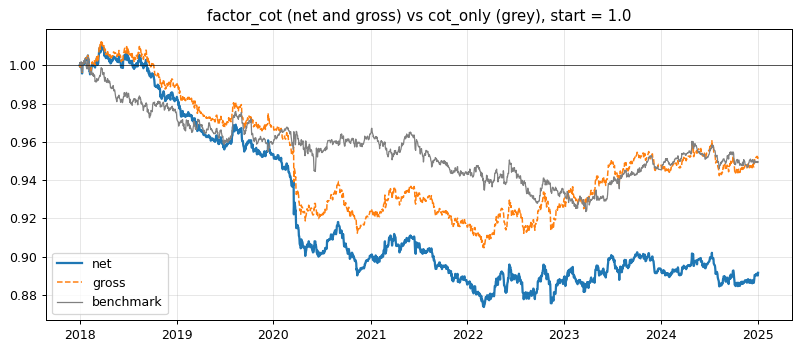

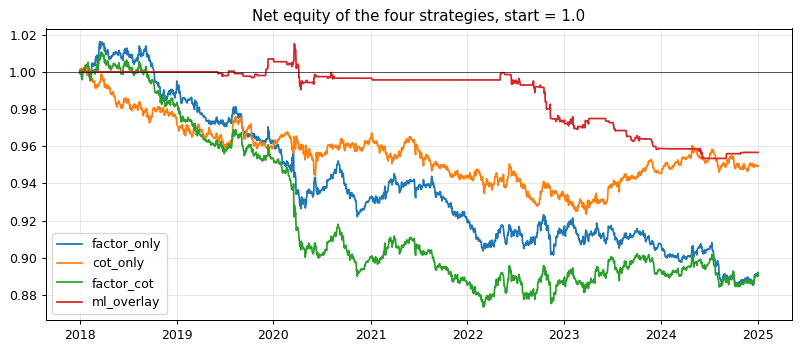

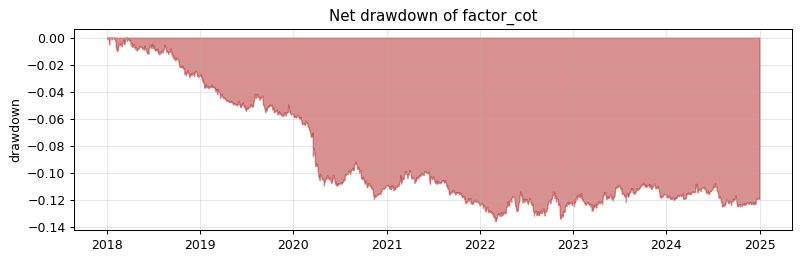

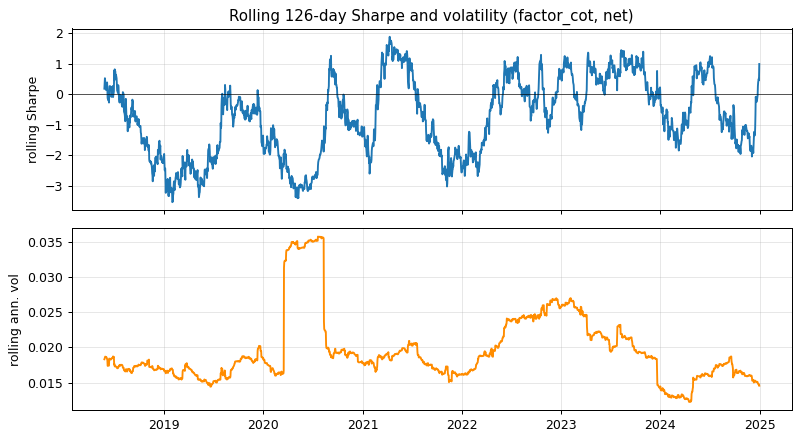

In [ ]:
fig = plot_equity(net[fc], gross=gross[fc], benchmark=net["cot_only"],
                  title="factor_cot (net and gross) vs cot_only (grey), start = 1.0")
plt.show()
fig, ax = plt.subplots(figsize=(9, 4))
for n in FRAMES:
    ax.plot((1.0 + net[n]).cumprod(), label=n, lw=1.4)
ax.axhline(1.0, color="k", lw=0.5)
ax.set_title("Net equity of the four strategies, start = 1.0")
ax.legend()
fig.tight_layout()
plt.show()
fig = plot_drawdown(net[fc], title="Net drawdown of factor_cot")
plt.show()
fig = plot_rolling_risk(net[fc], window=126, periods_per_year=ppy, title="Rolling 126-day Sharpe and volatility (factor_cot, net)")
plt.show()

### 9.2 Calendar views, distribution, exposure and turnover

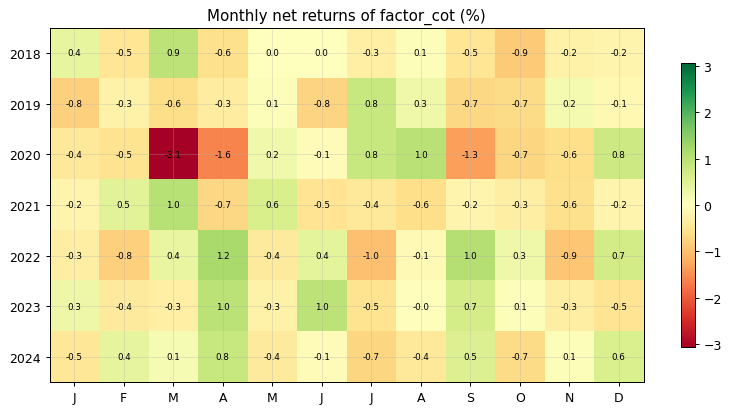

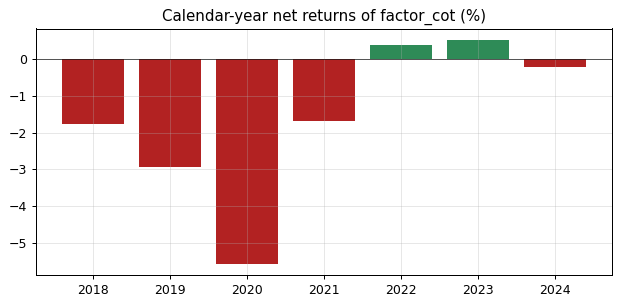

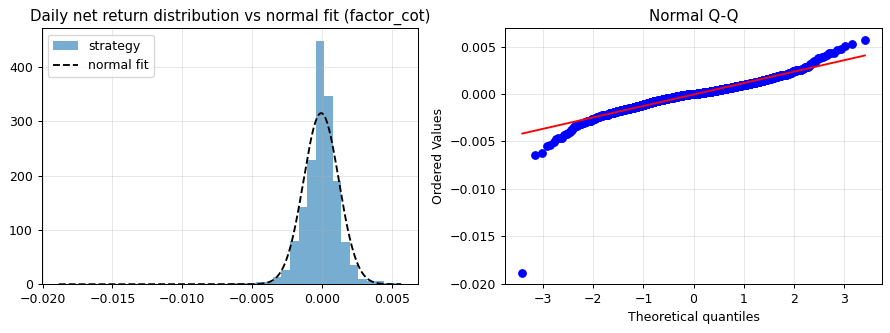

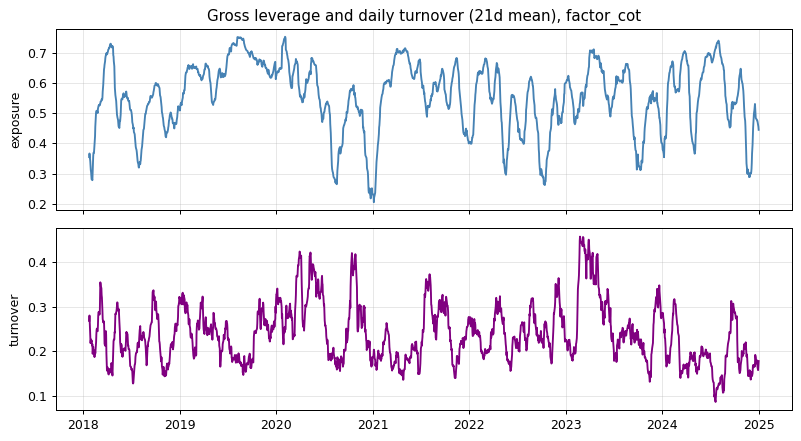

In [ ]:
fig = plot_monthly_heatmap(net[fc], title="Monthly net returns of factor_cot (%)")
plt.show()
fig = plot_yearly_bars(net[fc], title="Calendar-year net returns of factor_cot (%)")
plt.show()
fig = plot_return_distribution(net[fc], title="Daily net return distribution vs normal fit (factor_cot)")
plt.show()
fig = plot_exposure_turnover(dev[fc]["gross_leverage"].rolling(21).mean(), dev[fc]["turnover"].rolling(21).mean(),
                             title="Gross leverage and daily turnover (21d mean), factor_cot")
plt.show()

### 9.3 Cost decomposition, pair contribution and currency exposure

The first chart splits the development window of each strategy into gross P&L, the spread paid and the commission add-on (as shares of equity). The pair contribution is the gross P&L each pair earned for the headline strategy: a long-short book with no signal produces contributions of both signs and no pattern.

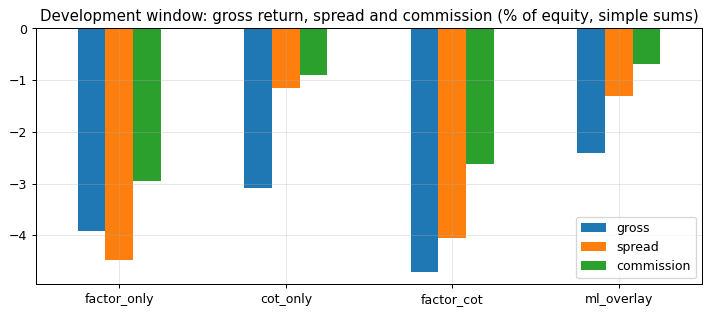

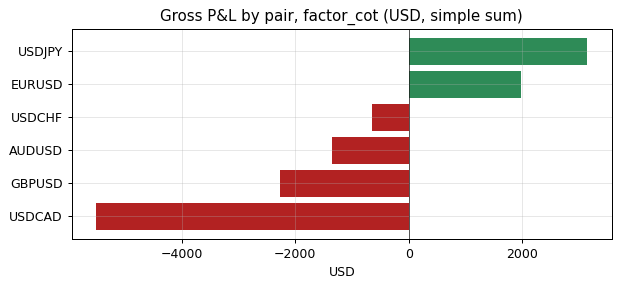

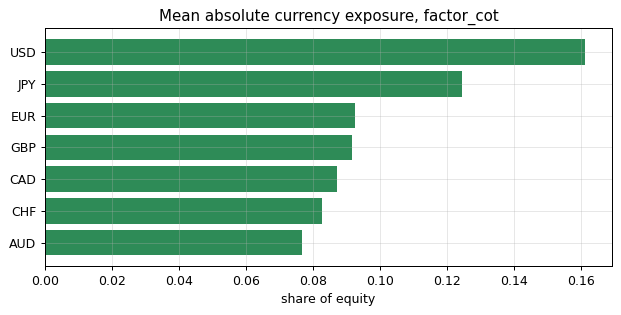

In [ ]:
cost_tbl = pd.DataFrame({n: {"gross": SUMMARY.loc[(n, "development"), "gross_total_return"], "spread": -SUMMARY.loc[(n, "development"), "spread_cost"],
                             "commission": -SUMMARY.loc[(n, "development"), "commission_cost"]} for n in FRAMES}).T * 100
fig, ax = plt.subplots(figsize=(8, 3.6))
cost_tbl.plot.bar(ax=ax, rot=0)
ax.axhline(0.0, color="k", lw=0.6)
ax.set_title("Development window: gross return, spread and commission (% of equity, simple sums)")
fig.tight_layout()
plt.show()
pair_gross = pd.Series({pair: float((dev[fc][f"held_{pair}"] * dev[fc][f"return_{pair}"].fillna(0.0)).sum()) * cap for pair in PAIRS})
fig = plot_bar_contribution(pair_gross, title="Gross P&L by pair, factor_cot (USD, simple sum)", xlabel="USD")
plt.show()
cur_exp = pd.DataFrame({cur: dev[fc][f"currency_{cur}"].abs() for cur in CURRENCIES}).mean()
fig = plot_bar_contribution(cur_exp, title="Mean absolute currency exposure, factor_cot", xlabel="share of equity")
plt.show()
RESULTS["pair_gross_positive_share"] = float((pair_gross > 0).mean())

## 10. The killing test: does the score carry any information?

Four checks that need no cost model.

1. **Rank IC.** Each day, the Spearman correlation across the seven currencies between the score and the **next** day's realised currency return. A signal with information has a mean IC above zero with a meaningful t-statistic; the t-statistic here treats days as independent, which flatters the signal, not the null.
2. **Directional hit rate.** How often the sign of the score matches the sign of the next day's currency return, with a binomial 95% interval.
3. **Permutation test on the book.** Shuffle the **days** of the held weights (each day's six weights stay together, so exposure, leverage and cross-sectional mix are preserved) against the realised pair returns, 2,000 times, and compare the gross P&L with the actual. If the actual gross sits inside the shuffled distribution the weights carry no timing information.
4. **Gross Sharpe interval.** A block bootstrap of the *gross* Sharpe (blocks of 10 days).

,ic_mean,ic_t,hit_rate,hit_lo,hit_hi
factor_only,0.0127,1.2644,0.5007,0.4926,0.5088
cot_only,-0.0045,-0.4865,0.5001,0.4921,0.5080
factor_cot,0.0131,1.3153,0.5024,0.4943,0.5105
ml_overlay,-0.0093,-0.2955,0.5056,0.4900,0.5213


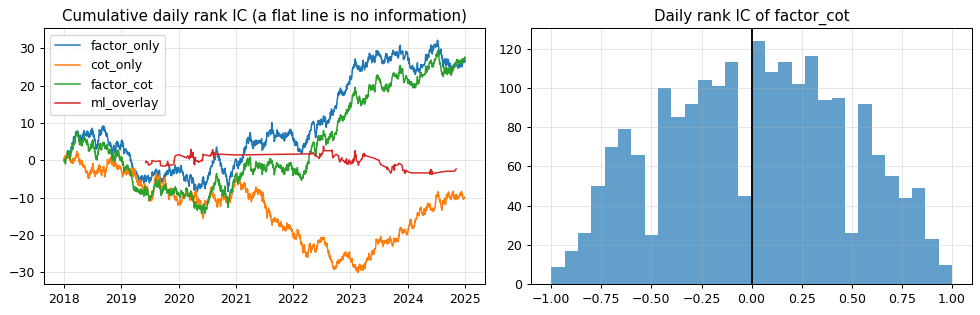

,actual_gross_sum,perm_mean,perm_p05,perm_p95,share_at_least_as_good
factor_only,-0.0381,0.0204,-0.0756,0.1134,0.8530
cot_only,-0.0299,0.0120,-0.0730,0.0972,0.7935
factor_cot,-0.0465,0.0176,-0.0742,0.1064,0.8725
ml_overlay,-0.0239,0.0014,-0.0298,0.0307,0.9160


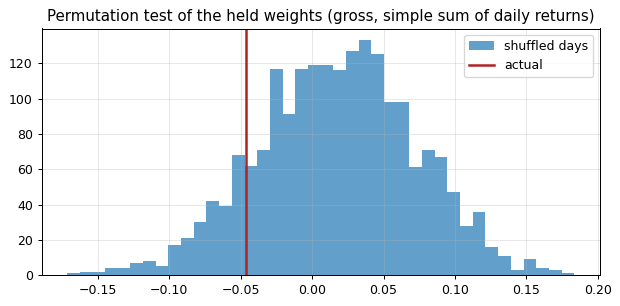

gross Sharpe of factor_cot: -0.27 (90% block-bootstrap interval [-0.76, 0.29])


In [ ]:
ic_rows, hit_rows = {}, {}
dev_mask = (FEAT["date"] >= PARAMS["development_start"]) & (FEAT["date"] <= PARAMS["development_end"])
ret_wide = FEAT.loc[dev_mask].pivot(index="date", columns="currency", values="next_currency_return")
for name, col in STRATEGY_SCORES.items():
    sc = FEAT.loc[dev_mask].pivot(index="date", columns="currency", values=col)
    ic = cross_sectional_rank_ic(sc, ret_wide, min_obs=5).dropna()
    both = pd.concat([sc.stack().rename("s"), ret_wide.stack().rename("r")], axis=1).dropna()
    both = both[both["r"] != 0]
    k, n = int((np.sign(both["s"]) == np.sign(both["r"])).sum()), len(both)
    ci = stats.binomtest(k, n, 0.5).proportion_ci(confidence_level=0.95)
    ic_rows[name] = {"days_with_ic": len(ic), "ic_mean": float(ic.mean()), "ic_t": float(ic.mean() / (ic.std() / np.sqrt(len(ic)))),
                     "hit_rate": k / n, "hit_lo": float(ci.low), "hit_hi": float(ci.high)}
    hit_rows[name] = ic
skill = pd.DataFrame(ic_rows).T
display(skill.drop(columns="days_with_ic").round(4))
RESULTS.update({"ic_fc_mean": float(skill.loc[fc, "ic_mean"]), "ic_fc_t": float(skill.loc[fc, "ic_t"]), "hit_fc": float(skill.loc[fc, "hit_rate"]),
                "hit_fc_lo": float(skill.loc[fc, "hit_lo"]), "hit_fc_hi": float(skill.loc[fc, "hit_hi"]),
                "skill": {n: {k: float(v) for k, v in row.items()} for n, row in ic_rows.items()}})

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for name, ic in hit_rows.items():
    axes[0].plot(ic.cumsum(), label=name, lw=1.2)
axes[0].set_title("Cumulative daily rank IC (a flat line is no information)")
axes[0].legend()
axes[1].hist(hit_rows[fc], bins=30, alpha=0.7)
axes[1].axvline(0, color="k")
axes[1].set_title("Daily rank IC of factor_cot")
fig.tight_layout()
plt.show()

rng = np.random.default_rng(int(PARAMS["random_seed"]))
perm_rows = {}
for name in FRAMES:
    d_ = dev[name]
    H = d_[[f"held_{pair}" for pair in PAIRS]].to_numpy()
    Rm = d_[[f"return_{pair}" for pair in PAIRS]].fillna(0.0).to_numpy()
    actual = float((H * Rm).sum())
    sims = np.empty(int(PARAMS["n_permutations"]))
    for b in range(len(sims)):
        sims[b] = float((H[rng.permutation(len(H))] * Rm).sum())
    perm_rows[name] = {"actual_gross_sum": actual, "perm_mean": float(sims.mean()), "perm_p05": float(np.quantile(sims, 0.05)),
                       "perm_p95": float(np.quantile(sims, 0.95)), "share_at_least_as_good": float((sims >= actual).mean())}
    if name == fc:
        fc_sims, fc_actual = sims, actual
perm = pd.DataFrame(perm_rows).T
display(perm.round(4))
RESULTS["perm_p_fc"] = float(perm.loc[fc, "share_at_least_as_good"])
RESULTS["perm"] = {n: {k: float(v) for k, v in row.items()} for n, row in perm_rows.items()}
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(fc_sims, bins=40, alpha=0.7, label="shuffled days")
ax.axvline(fc_actual, color="firebrick", lw=2, label="actual")
ax.set_title("Permutation test of the held weights (gross, simple sum of daily returns)")
ax.legend()
fig.tight_layout()
plt.show()
print(f"gross Sharpe of factor_cot: {RESULTS['fc_gross_sharpe']:.2f} (90% block-bootstrap interval "
      f"[{RESULTS['fc_gross_sharpe_lo']:.2f}, {RESULTS['fc_gross_sharpe_hi']:.2f}])")

### 10.1 The decision hurdles

The decision rule fixed hard hurdles in advance for the headline strategy in the development window: a CAGR between 5% and 15%; at least 30 trade events; a positive return in at least 60% of calendar years (and at least five years); a positive pair contribution in at least half of the pairs. The decision is "not eligible to proceed" unless all hold *and* a fresh, uninspected out-of-sample window exists, which it does not (the retrospective window has been looked at).

In [ ]:
yearly = dev[fc]["net_return"].groupby(dev[fc].index.year).apply(lambda s: float((1 + s).prod() - 1))
pair_ret = pd.Series({pair: float((dev[fc][f"held_{pair}"] * dev[fc][f"return_{pair}"].fillna(0.0)).sum()) for pair in PAIRS})
blockers = []
lo_b, hi_b = PARAMS["cagr_band"]
if not (lo_b <= float(d["cagr"]) <= hi_b):
    blockers.append(f"development CAGR is outside the stated {lo_b:.0%} to {hi_b:.0%} band")
if int(d["trade_count"]) < PARAMS["min_trades"]:
    blockers.append("minimum trade count not met")
if len(yearly) < 5 or float((yearly > 0).mean()) < PARAMS["year_positive_min"]:
    blockers.append("year stability not met (fewer than 60% of years positive)")
if float((pair_ret > 0).mean()) < PARAMS["pair_positive_min"]:
    blockers.append("pair stability not met (fewer than half of the pairs contribute positively)")
blockers.append("no fresh, uninspected out-of-sample window exists")
for b in blockers:
    print(" -", b)
RESULTS["blockers"] = blockers
RESULTS["years_positive_share"] = float((yearly > 0).mean())
RESULTS["pairs_positive_share_gross"] = float((pair_ret > 0).mean())

 - development CAGR is outside the stated 5% to 15% band
 - year stability not met (fewer than 60% of years positive)
 - pair stability not met (fewer than half of the pairs contribute positively)
 - no fresh, uninspected out-of-sample window exists


## 11. Capital sweep and cost sensitivity

### 11.1 Capital sweep

The headline equity of 100,000 USD is an illustrative assumption, so the development record is re-read at six equity levels. **Only the initial equity changes**: signals, caps, windows and costs are identical and nothing is retuned. The book holds weights as fractions of equity and its costs are proportional to the traded amount (a half-spread and a basis-point commission), so there is no fixed per-order fee and no minimum ticket to bite. Every ratio is therefore identical at every level and the USD amounts scale linearly; the table shows that rather than assuming it.

capital,5000,10000,25000,50000,100000,250000
gross_usd,-235.379,-470.758,-1176.894,-2353.788,-4707.575,-11768.938
net_usd,-542.502,-1085.004,-2712.510,-5425.021,-10850.042,-27125.105
cost_usd,307.123,614.247,1535.617,3071.233,6142.467,15356.167
net_return,-10.850,-10.850,-10.850,-10.850,-10.850,-10.850
cost_share,6.142,6.142,6.142,6.142,6.142,6.142
sharpe,-0.649,-0.649,-0.649,-0.649,-0.649,-0.649
max_drawdown,-13.557,-13.557,-13.557,-13.557,-13.557,-13.557


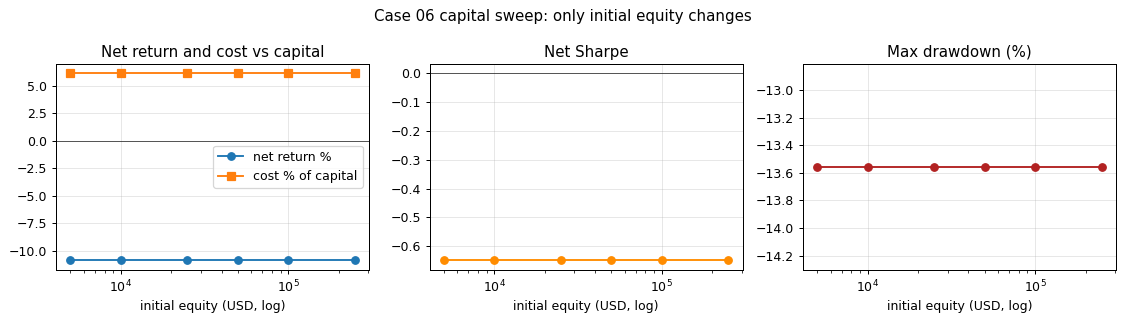

In [ ]:
def run_at_capital(cap_: float) -> Dict[str, float]:
    sm = performance_summary(net[fc], periods_per_year=ppy)
    eq = cap_ * (1.0 + net[fc]).cumprod()
    gross_usd = float(cap_ * ((1.0 + gross[fc]).prod() - 1.0))
    net_usd = float(eq.iloc[-1] - cap_)
    return {"gross_usd": gross_usd, "net_usd": net_usd, "cost_usd": gross_usd - net_usd, "net_return": net_usd / cap_,
            "cost_share": (gross_usd - net_usd) / cap_, "sharpe": float(sm["sharpe"]), "max_drawdown": float(sm["max_drawdown"])}


_caps = [5_000, 100_000] if SYNTHETIC else [5_000, 10_000, 25_000, 50_000, 100_000, 250_000]
cap_sweep = capital_sweep(run_at_capital, _caps)
show = cap_sweep.copy()
for col in ["net_return", "cost_share", "max_drawdown"]:
    show[col] = (show[col] * 100).round(3)
display(show.round(3).set_index("capital").T)
plot_capital_sweep(cap_sweep, title="Case 04 capital sweep: only initial equity changes")
plt.show()
RESULTS["capital_sweep"] = cap_sweep.round(6).to_dict("records")
RESULTS["sweep_net_return_spread"] = float(cap_sweep["net_return"].max() - cap_sweep["net_return"].min())

### 11.2 Cost multiplier

Net P&L on the day is `gross + m x (spread + commission)`. Scaling the whole cost by `m` (re-running the portfolio, not re-using a number) shows whether any cost level makes the book profitable. If gross is not positive there is **no** `m` at which it breaks even.

In [ ]:
rows = []
for m in (0.0, 0.5, 1.0, 2.0):
    fr = run_portfolio(TARGETS[fc], QUOTES, dict(PARAMS, cost_multiplier=m))
    s = window_metrics(window(fr, "development", PARAMS), PARAMS)
    rows.append({"cost_multiplier": m, "total_return": s["total_return"], "cagr": s["cagr"], "sharpe": s["sharpe"]})
cost_sweep = pd.DataFrame(rows).set_index("cost_multiplier")
display(cost_sweep.round(4))
RESULTS["cost_sweep"] = cost_sweep.round(6).reset_index().to_dict("records")
RESULTS["fc_total_cost0"] = float(cost_sweep.loc[0.0, "total_return"])
RESULTS["fc_sharpe_cost0"] = float(cost_sweep.loc[0.0, "sharpe"])
RESULTS["fc_total_cost2"] = float(cost_sweep.loc[2.0, "total_return"])

,total_return,cagr,sharpe
cost_multiplier,,,
0.0,-0.0471,-0.0069,-0.2670
0.5,-0.0783,-0.0116,-0.4584
1.0,-0.1085,-0.0163,-0.6494
2.0,-0.1660,-0.0256,-1.0295


## 12. Sensitivity: the weekly variant (lower turnover, same factors)

The weekly variant tests whether *daily noise and turnover*, rather than model complexity, explain the weak result. The weekly variant keeps the factor idea and changes only the cadence and the turnover controls, fixed in advance:

* **Cadence.** The signal is formed at the last common close of each Friday-ending week and is traded at the **next** common close, earning returns only from the close after that (a conservative extra day of delay).
* **Factors.** Medium (63-day) and slow (126-day) momentum, a 5-day reversal that only counts while the medium trend is weak (`|z| <= 1`) at 25% weight, volatility scaling; positioning with a 30% weight and a **disagreement multiplier** of 0.5 when the positioning and the factor have opposite signs. No policy-rate input, no overlay.
* **Turnover controls.** A currency may change sign only after the new sign has persisted for **two** weekly anchors, and the book is rebalanced only when the largest single-currency weight change reaches 5 percentage points.
* The same capped, currency-neutral construction, the same costs.

weekly variant built in 7.6s


,total_return,cagr,sharpe,max_drawdown,trade_count,turnover,gross_total_return
daily factor_cot,-10.85%,-1.63%,-0.65,-13.56%,"2,156",524.2,-4.71%
weekly factor_cot,-6.13%,-0.90%,-0.32,-7.89%,297,80.0,-5.60%
weekly factor_only,-8.00%,-1.18%,-0.42,-9.41%,305,85.2,-7.45%
weekly cot_only,-2.43%,-0.35%,-0.15,-7.39%,255,63.4,-1.99%


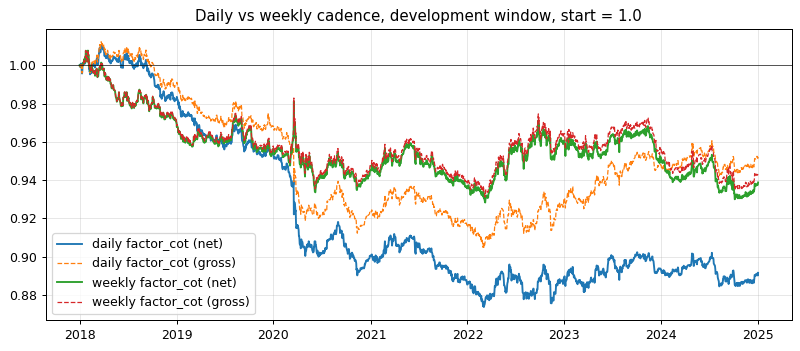

In [ ]:
def weekly_features(quotes: Mapping[str, pd.DataFrame], cot: pd.DataFrame, w: Dict[str, Any], p: Dict[str, Any]) -> pd.DataFrame:
    rows = []
    for pair, quote in quotes.items():
        base, term = PAIR_CURRENCIES[pair]
        daily = quote.copy().rename_axis("date").reset_index()
        lp = np.log(daily["mid_close"])
        daily["medium_momentum"] = lp.diff(w["medium_momentum_days"])
        daily["slow_momentum"] = lp.diff(w["slow_momentum_days"])
        daily["short_reversal"] = -lp.diff(w["short_reversal_days"])
        daily["pair_volatility"] = daily["mid_return"].rolling(w["volatility_days"], min_periods=w["volatility_days"]).std(ddof=1)
        for currency, sign in ((base, 1.0), (term, -1.0)):
            part = daily[["date", "medium_momentum", "slow_momentum", "short_reversal", "pair_volatility"]].copy()
            part["currency"] = currency
            for c in ("medium_momentum", "slow_momentum", "short_reversal"):
                part[c] *= sign
            rows.append(part)
    cur = pd.concat(rows, ignore_index=True).groupby(["date", "currency"], as_index=False).mean(numeric_only=True)
    cur = robust_zscore(cur, ["medium_momentum", "slow_momentum", "short_reversal"])
    cur["momentum_score"] = 0.5 * cur["z_medium_momentum"] + 0.5 * cur["z_slow_momentum"]
    cur["reversal_gate"] = (cur["z_medium_momentum"].abs() <= w["short_reversal_trend_gate_z"]).astype(float)
    cur["factor_score"] = cur["momentum_score"] + w["short_reversal_weight"] * cur["reversal_gate"] * cur["z_short_reversal"]
    cur["cross_section_dispersion"] = cur.groupby("date")["factor_score"].transform("std")
    dates = cur[["date", "currency"]].drop_duplicates().sort_values(["currency", "date"])
    cot_rows = []
    for currency, left in dates.groupby("currency", sort=False):
        src = cot.loc[cot["currency"] == currency, ["assumed_availability_date", "report_date", "net_leveraged_pct_open_interest",
                                                    "cot_zscore"]].sort_values("assumed_availability_date")
        cot_rows.append(pd.merge_asof(left.sort_values("date"), src, left_on="date", right_on="assumed_availability_date",
                                      direction="backward", allow_exact_matches=True))
    cur = cur.merge(pd.concat(cot_rows, ignore_index=True), on=["date", "currency"], how="left", validate="one_to_one")
    cur["cot_feature"] = cur["cot_zscore"].clip(-3.0, 3.0)
    same = np.sign(cur["factor_score"]) == np.sign(cur["cot_feature"])
    cur["cot_confirmation_multiplier"] = np.where(cur["cot_feature"].isna() | same, 1.0, w["cot_disagreement_multiplier"])
    cur["factor_cot_score"] = ((1.0 - w["cot_weight"]) * cur["factor_score"] + w["cot_weight"] * cur["cot_feature"]) * cur["cot_confirmation_multiplier"]
    return cur.sort_values(["date", "currency"]).reset_index(drop=True)


def weekly_anchors(features: pd.DataFrame, score_column: str, p: Dict[str, Any]) -> pd.DataFrame:
    days = pd.Series(sorted(pd.Timestamp(v) for v in features["date"].unique()))
    days.index = days
    anchors = [pd.Timestamp(g.iloc[-1]) for _, g in days.groupby(days.index.to_period("W-FRI"))]
    rows = []
    for anchor in anchors:
        group = features.loc[features["date"] == anchor].set_index("currency").reindex(list(CURRENCIES))
        disp = float(group["cross_section_dispersion"].iloc[0]) if len(group) else math.nan
        exposure, state = bounded_exposures(group[score_column], group["pair_volatility"], disp, p)
        row = {"anchor_date": anchor, "state": state}
        for cur in CURRENCIES:
            row[f"score_{cur}"] = float(group.loc[cur, score_column]) if pd.notna(group.loc[cur, score_column]) else np.nan
            row[f"currency_{cur}"] = float(exposure.loc[cur])
        rows.append(row)
    return pd.DataFrame(rows)


def enforce_constraints(exposure: pd.Series, p: Dict[str, Any]) -> pd.Series:
    cap, target = p["currency_exposure_cap"], p["target_gross_exposure"]
    result = exposure.astype(float).copy()
    result -= result.mean()
    gross_ = float(result.abs().sum())
    if gross_ > target:
        result *= target / gross_
    result = result.clip(-cap, cap)
    residual = float(result.sum())
    if abs(residual) > 1e-15:
        capacity = result + cap if residual > 0 else cap - result
        if float(capacity.sum()) + 1e-12 < abs(residual):
            raise RuntimeError("persistence projection cannot restore currency neutrality within the cap")
        result -= residual * capacity / float(capacity.sum())
    return result


def apply_persistence_and_buffer(cands: pd.DataFrame, w: Dict[str, Any], p: Dict[str, Any]) -> pd.DataFrame:
    out = cands.copy().sort_values("anchor_date").reset_index(drop=True)
    wcols, scols = [f"currency_{c}" for c in CURRENCIES], [f"score_{c}" for c in CURRENCIES]
    current = pd.Series(0.0, index=wcols)
    prev_sign = pd.Series(0.0, index=scols)
    streak = pd.Series(0, index=scols, dtype=int)
    n_rebalances = 0
    for i, row in out.iterrows():
        cand = row[wcols].astype(float)
        new_sign = np.sign(row[scols].astype(float).fillna(0.0))
        streak = pd.Series(np.where(new_sign == prev_sign, streak + 1, 1), index=scols, dtype=int)
        prev_sign = new_sign
        sign_change = np.sign(cand.to_numpy()) != np.sign(current.to_numpy())
        approved = (streak.to_numpy() >= w["signal_persistence_weeks"]) | ~sign_change
        filtered = current.copy()
        filtered.iloc[np.where(approved)[0]] = cand.iloc[np.where(approved)[0]].to_numpy()
        filtered = enforce_constraints(filtered, p)
        changed = float((filtered - current).abs().max()) >= w["turnover_buffer_max_weight_change"]
        if changed:
            current = filtered
            n_rebalances += 1
        for j, col in enumerate(wcols):
            out.loc[i, col] = current.iloc[j]
    for pair, (base, term) in PAIR_CURRENCIES.items():
        out[f"weight_{pair}"] = out[f"currency_{base}"] if term == "USD" else -out[f"currency_{term}"]
    out.attrs["rebalances"] = n_rebalances
    return out


def run_weekly_portfolio(buffered: pd.DataFrame, quotes: Mapping[str, pd.DataFrame], p: Dict[str, Any]) -> pd.DataFrame:
    common = pd.DatetimeIndex(sorted(set.intersection(*(set(q.index) for q in quotes.values()))))
    exec_dates = []
    for anchor in buffered["anchor_date"]:
        later = common[common > pd.Timestamp(anchor)]
        exec_dates.append(pd.Timestamp(later[0]) if len(later) else pd.NaT)
    ex = buffered.assign(execution_date=exec_dates)
    ex = ex[ex["execution_date"].notna()]
    targets = ex.set_index("execution_date")
    frame = pd.DataFrame({"date": common})
    for pair, q in quotes.items():
        frame = frame.merge(q[["mid_return", "half_spread_bps"]].rename_axis("date").reset_index().rename(
            columns={"mid_return": f"return_{pair}", "half_spread_bps": f"half_spread_bps_{pair}"}), on="date", how="left", validate="one_to_one")
        frame[f"weight_{pair}"] = frame["date"].map(targets[f"weight_{pair}"]).ffill().fillna(0.0)
    frame["gross_leverage"] = frame[[f"weight_{pair}" for pair in PAIRS]].abs().sum(axis=1)
    for pair in PAIRS:
        frame[f"held_{pair}"] = frame[f"weight_{pair}"].shift(1).fillna(0.0)
        frame[f"turnover_{pair}"] = (frame[f"weight_{pair}"] - frame[f"weight_{pair}"].shift(1).fillna(0.0)).abs()
    frame["gross_return"] = sum(frame[f"held_{pair}"] * frame[f"return_{pair}"].fillna(0.0) for pair in PAIRS)
    frame["spread_cost"] = -sum(frame[f"turnover_{pair}"] * frame[f"half_spread_bps_{pair}"].fillna(0.0) / 10_000.0 for pair in PAIRS) * p["cost_multiplier"]
    frame["commission_cost"] = -p["commission_bps_one_way"] / 10_000.0 * sum(frame[f"turnover_{pair}"] for pair in PAIRS) * p["cost_multiplier"]
    frame["net_return"] = frame["gross_return"] + frame["spread_cost"] + frame["commission_cost"]
    frame["turnover"] = sum(frame[f"turnover_{pair}"] for pair in PAIRS)
    frame["trade_event"] = (frame["turnover"] > 1e-12).astype(int)
    return frame


t0 = time.time()
WFEAT = weekly_features(QUOTES, COT, WEEKLY, PARAMS)
WEEKLY_SCORES = {"weekly_factor_only": "factor_score", "weekly_cot_only": "cot_feature", "weekly_factor_cot": "factor_cot_score"}
WFRAMES = {}
for name, col in WEEKLY_SCORES.items():
    buffered = apply_persistence_and_buffer(weekly_anchors(WFEAT, col, PARAMS), WEEKLY, PARAMS)
    WFRAMES[name] = run_weekly_portfolio(buffered, QUOTES, PARAMS)
WSUMMARY = pd.DataFrame({(name, scope): window_metrics(window(fr, scope, PARAMS), PARAMS)
                         for name, fr in WFRAMES.items() for scope in ("development", "retrospective")}).T
print(f"weekly variant built in {time.time() - t0:.1f}s")
cmp = pd.DataFrame({
    "daily factor_cot": SUMMARY.loc[(fc, "development")],
    "weekly factor_cot": WSUMMARY.loc[("weekly_factor_cot", "development")],
    "weekly factor_only": WSUMMARY.loc[("weekly_factor_only", "development")],
    "weekly cot_only": WSUMMARY.loc[("weekly_cot_only", "development")]}).T
show = cmp[["total_return", "cagr", "sharpe", "max_drawdown", "trade_count", "turnover", "gross_total_return"]].copy()
for c in ["total_return", "cagr", "max_drawdown", "gross_total_return"]:
    show[c] = show[c].map(lambda v: f"{v * 100:.2f}%")
show["sharpe"] = show["sharpe"].map(lambda v: f"{v:.2f}")
show["trade_count"] = show["trade_count"].map(lambda v: f"{v:,.0f}")
show["turnover"] = show["turnover"].map(lambda v: f"{v:,.1f}")
display(show)
wdev = window(WFRAMES["weekly_factor_cot"], "development", PARAMS).set_index("date")
w_net, w_gross = wdev["net_return"].fillna(0.0), wdev["gross_return"].fillna(0.0)
w_blk_g = block_bootstrap_sharpe(w_gross, block=10, n_boot=int(PARAMS["n_bootstrap"]), seed=int(PARAMS["random_seed"]))
w_blk_n = block_bootstrap_sharpe(w_net, block=10, n_boot=int(PARAMS["n_bootstrap"]), seed=int(PARAMS["random_seed"]))
wd = WSUMMARY.loc[("weekly_factor_cot", "development")]
wr = WSUMMARY.loc[("weekly_factor_cot", "retrospective")]
RESULTS.update({"wk_dev_total": float(wd["total_return"]), "wk_dev_cagr": float(wd["cagr"]), "wk_dev_sharpe": float(wd["sharpe"]),
                "wk_dev_mdd": float(wd["max_drawdown"]), "wk_dev_trades": int(wd["trade_count"]), "wk_turnover": float(wd["turnover"]),
                "wk_gross_total": float(wd["gross_total_return"]), "wk_retro_total": float(wr["total_return"]),
                "wk_gross_sharpe": float(math.sqrt(ppy) * w_gross.mean() / w_gross.std(ddof=1)),
                "wk_gross_sharpe_lo": float(w_blk_g["lo"]), "wk_gross_sharpe_hi": float(w_blk_g["hi"]),
                "wk_net_sharpe_lo": float(w_blk_n["lo"]), "wk_net_sharpe_hi": float(w_blk_n["hi"]),
                "turnover_ratio_weekly": float(1.0 - wd["turnover"] / d["turnover"]),
                "weekly_dev": {n: {k: float(WSUMMARY.loc[(n, "development"), k]) for k in ("total_return", "cagr", "sharpe", "max_drawdown", "trade_count", "turnover", "gross_total_return")} for n in WFRAMES},
                "weekly_retro": {n: {k: float(WSUMMARY.loc[(n, "retrospective"), k]) for k in ("total_return", "cagr", "sharpe")} for n in WFRAMES}})
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot((1.0 + net[fc]).cumprod(), label="daily factor_cot (net)", lw=1.5)
ax.plot((1.0 + gross[fc]).cumprod(), label="daily factor_cot (gross)", lw=1.0, ls="--")
ax.plot((1.0 + w_net).cumprod(), label="weekly factor_cot (net)", lw=1.5)
ax.plot((1.0 + w_gross).cumprod(), label="weekly factor_cot (gross)", lw=1.0, ls="--")
ax.axhline(1.0, color="k", lw=0.5)
ax.set_title("Daily vs weekly cadence, development window, start = 1.0")
ax.legend()
fig.tight_layout()
plt.show()

## 13. Interpretation

**Headline, at 100,000 USD of illustrative equity.** The spot factor + positioning + rate strategy loses -10.9% net over the development window (-10,850 USD), a CAGR of -1.63%, annualised Sharpe -0.65, maximum drawdown -13.6%. Gross of costs it is -4.7% (gross Sharpe -0.27, 90% interval [-0.76, 0.29]); the spread paid is 4.0% and the commission 2.6% of equity (simple sums), on a summed absolute weight change of about 524. The retrospective window, not used for any choice, is -2.3%. The decision rule fails on the CAGR band and on the stability of years and pairs (section 10.1) and on the absence of a fresh holdout; the answer, "not eligible to proceed", stands.

**No signal is the finding.** The mean rank IC of the headline score is 0.0131 with t = 1.32; the hit rate is 50.2% with interval [49.4%, 51.1%]; the permutation test places the actual gross P&L at the 87% level (the share of shuffled weights that did at least as well is 0.87). Nothing about the held weights is informative about the next day's return, before any cost. The other three strategies agree (section 10 table): none has a mean rank IC with a t-statistic near two, every hit-rate interval contains one half, and every permutation share is far from the 5% that would indicate timing information. The secondary overlay changes the number of trading days far more than it changes the information: it is active on only 11% of days (it needs a trained model and a probability more than four points from one half), and on those days it earns no more than the others.

**Costs then make it certain.** The book turns over heavily because the daily scores of seven currencies move every day, and each rebalance pays the quoted half-spread and the commission add-on. The cost sweep re-runs the portfolio: at zero cost the headline returns -4.7% (Sharpe -0.27), at the modelled cost -10.9%, at twice the cost -16.6%. There is no multiplier that makes it profitable, because gross is not positive. Because the book is a fixed share of equity and its costs are proportional, the capital sweep returns identical ratios at every level (largest difference in net return 6.9e-17): this is not a small-account story.

**The weekly variant changes the size of the loss, not its sign.** With a Friday anchor, persistence gate, turnover buffer and next-close execution, turnover falls by about 85%; the headline weekly strategy returns -6.1% net (CAGR -0.90%, Sharpe -0.32) and -5.6% gross, with a gross Sharpe interval of [-0.80, 0.20]. Less trading loses less, because there is less cost to pay on a signal that earns nothing.

**Honest label.** No signal is the primary tag: the information tests fail without a cost model. Cost model is secondary, because a book that earns zero gross and trades this much has a loss set by the quoted spread and the commission.

## 14. The lesson

**A factor is not a signal until its information survives a test that needs no costs.** Free, published, economically motivated inputs, assembled into a clean, capped, currency-neutral, delay-conservative book, are still only a hypothesis about next-day returns. Compute the rank IC, the hit-rate interval and a day-shuffle permutation of the held weights first; they take seconds and they are immune to every execution and cost assumption. If they say "no information", the work left is not the portfolio, it is the hypothesis.

## 15. What I would do differently

* **Run the information tests before building the book.** The IC and the permutation test need a score matrix and next-day returns, nothing else.
* **Choose the horizon from the signal.** Positioning and policy rates are slow; spot momentum is slowish. A daily rebalance of a weekly signal is mostly noise turnover. The weekly variant should have been the first test, not the follow-up.
* **Use pooled evidence.** Seven currencies and one decade give few independent observations of a slow factor. Add more currencies (crosses, other regions) and more history before reading year-by-year stability.
* **Keep a genuinely untouched holdout.** The retrospective window had been inspected before this write-up; it cannot rescue or condemn anything.

## 16. How to improve it (ideas, not claims)

* Replace the free spot factors with a forward-looking measure (implied-volatility skew, forward points) that is not already in the price.
* Use positioning *changes* and extremes, not levels, and a release timestamp from a vendor that records it.
* Model carry properly (forward points or broker financing) instead of a policy-rate level used as a cross-sectional z-score.
* Vol-target the whole book and trade only when the expected edge exceeds the half-spread.

## 17. FAQ

**Why a robust (median and MAD) z-score across only seven currencies?** With seven points a mean and standard deviation are dominated by one outlier; the median and MAD are not. The constants are fixed in advance.

**Is the COT lag conservative or realistic?** Conservative: the report is usually public on the Friday after the Tuesday it describes, and the notebook waits until the next Monday. A looser lag would add information the strategy could not have had.

**Why not tune the windows?** There is no information to tune. A search over windows on a score with a mean rank IC this close to zero would only fit noise; the constants are fixed in advance for that reason.

**Is USD positioning from the dollar index future comparable to the others?** Not exactly: it comes from a different exchange and contract design. The notebook maps it as a USD-strength instrument; this is a listed limitation.

**Does the failure reproduce in synthetic mode?** No. Synthetic quotes are random walks and the synthetic positioning and rates have no relation to them; the notebook only demonstrates that the code runs end to end.

## 18. References

* Menkhoff, L., Sarno, L., Schmeling, M. and Schrimpf, A. (2012). Currency momentum strategies. *Journal of Financial Economics*, 106, 660-684.
* Asness, C., Moskowitz, T. and Pedersen, L. H. (2013). Value and momentum everywhere. *Journal of Finance*, 68, 929-985.
* Commodity Futures Trading Commission. *Commitments of Traders: Traders in Financial Futures* (public reports and historical compressed files).
* Bank for International Settlements. Central bank policy rates (data portal bulk downloads).
* Bailey, D. H. and Lopez de Prado, M. (2014). The deflated Sharpe ratio. *Journal of Portfolio Management*.
* Efron, B. and Tibshirani, R. (1993). *An Introduction to the Bootstrap.* Chapman and Hall.

## 19. Disclaimer

This notebook is educational. It documents a failed research experiment and is not financial advice or a recommendation to trade any instrument. Leveraged FX trading involves substantial risk of loss. Past or hypothetical results do not predict future results. Policy rates are a proxy, not tradable carry. The code is provided as is, without warranty.

In [ ]:
if os.environ.get("AUTOPSY_RESULTS_JSON"):
    Path(os.environ["AUTOPSY_RESULTS_JSON"]).write_text(json.dumps(RESULTS, indent=2, default=str))
print("done")

done
